In [80]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler

In [81]:
pd.set_option('display.max_columns', None)


In [82]:
df = pd.read_csv('../data/processed/housing_data_engineered.csv', parse_dates=['date'])
print("Loaded data shape:", df.shape)
df.head()

Loaded data shape: (262780, 64)


,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full,month,quarter,list_sale_gap,ppsf_gap,future_price_6m,price_change_6m_pct,downturn_risk,price_ma_3m,price_ma_6m,price_ma_12m,price_mom,price_volatility_3m,price_volatility_6m,stl_momentum,inventory_turnover,dom_trend,price_lag_3m,inventory_lag_3m,sales_lag_3m,price_lag_6m,inventory_lag_6m,sales_lag_6m,price_lag_12m,inventory_lag_12m,sales_lag_12m
0,2013-03-31,182000.0,276700.0,113.750000,106.297939,5.0,9.0,6.0,13.0,157.0,0.983037,0.200000,0.111111,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,202747.875189,Boston-Cambridge-Newton,3,1,0.342248,-0.070105,209950.0,15.357143,0,153000.000000,166875.000000,164229.166667,41.634241,27032.387982,29227.448572,1.444382,0.357143,82.558140,148500.0,16.0,10.0,191000.0,29.0,8.0,89000.0,12.0,3.0
1,2013-04-30,210250.0,239900.0,105.398090,104.591492,10.0,11.0,11.0,15.0,137.5,0.946833,0.200000,0.181818,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,204051.871014,Boston-Cambridge-Newton,4,2,0.123593,-0.007712,249900.0,18.858502,0,173583.333333,167958.333333,171416.666667,15.521978,41519.824582,30938.009255,-3.682806,0.625000,-12.420382,148500.0,17.0,6.0,203750.0,24.0,10.0,124000.0,15.0,4.0
2,2013-05-31,210250.0,239900.0,105.398090,123.958333,10.0,8.0,15.0,17.0,180.5,0.943685,0.200000,0.250000,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,204630.025129,Boston-Cambridge-Newton,5,2,0.123593,0.149730,239350.0,13.840666,0,200833.333333,171333.333333,174145.833333,0.000000,16310.145105,34699.303547,-0.332489,0.555556,31.272727,128500.0,15.0,3.0,190000.0,22.0,12.0,177500.0,17.0,6.0
3,2013-06-30,208000.0,249900.0,108.856265,130.275689,8.0,7.0,15.0,19.0,148.5,0.933356,0.250000,0.285714,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,205382.144699,Boston-Cambridge-Newton,6,2,0.167667,0.164416,239350.0,15.072115,0,209500.000000,181250.000000,173395.833333,-1.070155,1299.038106,35364.530253,-1.094527,0.400000,-17.728532,182000.0,13.0,5.0,148500.0,16.0,10.0,217000.0,22.0,5.0
4,2013-07-31,179000.0,254900.0,124.146493,122.916667,3.0,4.0,12.0,22.0,204.0,0.971234,0.333333,0.250000,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,206779.514184,Boston-Cambridge-Newton,7,3,0.297764,-0.010005,230000.0,28.491620,0,199083.333333,186333.333333,177479.166667,-13.942308,17429.022730,31719.736233,4.058173,0.130435,37.373737,210250.0,15.0,10.0,148500.0,17.0,6.0,130000.0,22.0,5.0


In [83]:
print("Columns:", df.columns.tolist())
print("\nFirst row:", df.iloc[0].to_dict())
print(df.dtypes)

Columns: ['date', 'median_sale_price', 'median_list_price', 'median_ppsf', 'median_list_ppsf', 'homes_sold', 'pending_sales', 'new_listings', 'inventory', 'median_dom', 'avg_sale_to_list', 'sold_above_list', 'off_market_in_two_weeks', 'city', 'zipcode', 'year', 'bank', 'bus', 'hospital', 'mall', 'park', 'restaurant', 'school', 'station', 'supermarket', 'Total Population', 'Median Age', 'Per Capita Income', 'Total Families Below Poverty', 'Total Housing Units', 'Median Rent', 'Median Home Value', 'Total Labor Force', 'Unemployed Population', 'Total School Age Population', 'Total School Enrollment', 'Median Commute Time', 'price', 'city_full', 'month', 'quarter', 'list_sale_gap', 'ppsf_gap', 'future_price_6m', 'price_change_6m_pct', 'downturn_risk', 'price_ma_3m', 'price_ma_6m', 'price_ma_12m', 'price_mom', 'price_volatility_3m', 'price_volatility_6m', 'stl_momentum', 'inventory_turnover', 'dom_trend', 'price_lag_3m', 'inventory_lag_3m', 'sales_lag_3m', 'price_lag_6m', 'inventory_lag_6m'

In [84]:
X = df.drop(columns=['date'])
X = pd.get_dummies(X, columns=['city', 'city_full'], drop_first=True)
X = X.astype(float)
non_numeric_cols = X.select_dtypes(exclude=['number']).columns
print(non_numeric_cols)

Index([], dtype='object')


In [85]:
#Scale the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [86]:
#pca to reduce dimensionality to 6
print("\nRun PCA - [six dimensions]...")

n_components = 6
pca= PCA(n_components)
pcaX = pca.fit_transform(X_scaled)
#first 80% train, remaining 20% test
pcaX_train = pcaX[:int(0.8*len(pcaX))]
pcaX_test = pcaX[int(0.8*len(pcaX)):]


Run PCA - [six dimensions]...


In [87]:
kmeans = KMeans(n_clusters=2, random_state=42).fit(pcaX)
centroids = kmeans.cluster_centers_ #[256,n]
clusters = kmeans.labels_ #[m,]
df['cluster'] = clusters

In [88]:
df.head()

,date,median_sale_price,median_list_price,median_ppsf,median_list_ppsf,homes_sold,pending_sales,new_listings,inventory,median_dom,avg_sale_to_list,sold_above_list,off_market_in_two_weeks,city,zipcode,year,bank,bus,hospital,mall,park,restaurant,school,station,supermarket,Total Population,Median Age,Per Capita Income,Total Families Below Poverty,Total Housing Units,Median Rent,Median Home Value,Total Labor Force,Unemployed Population,Total School Age Population,Total School Enrollment,Median Commute Time,price,city_full,month,quarter,list_sale_gap,ppsf_gap,future_price_6m,price_change_6m_pct,downturn_risk,price_ma_3m,price_ma_6m,price_ma_12m,price_mom,price_volatility_3m,price_volatility_6m,stl_momentum,inventory_turnover,dom_trend,price_lag_3m,inventory_lag_3m,sales_lag_3m,price_lag_6m,inventory_lag_6m,sales_lag_6m,price_lag_12m,inventory_lag_12m,sales_lag_12m,cluster
0,2013-03-31,182000.0,276700.0,113.750000,106.297939,5.0,9.0,6.0,13.0,157.0,0.983037,0.200000,0.111111,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,202747.875189,Boston-Cambridge-Newton,3,1,0.342248,-0.070105,209950.0,15.357143,0,153000.000000,166875.000000,164229.166667,41.634241,27032.387982,29227.448572,1.444382,0.357143,82.558140,148500.0,16.0,10.0,191000.0,29.0,8.0,89000.0,12.0,3.0,0
1,2013-04-30,210250.0,239900.0,105.398090,104.591492,10.0,11.0,11.0,15.0,137.5,0.946833,0.200000,0.181818,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,3.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,204051.871014,Boston-Cambridge-Newton,4,2,0.123593,-0.007712,249900.0,18.858502,0,173583.333333,167958.333333,171416.666667,15.521978,41519.824582,30938.009255,-3.682806,0.625000,-12.420382,148500.0,17.0,6.0,203750.0,24.0,10.0,124000.0,15.0,4.0,0
2,2013-05-31,210250.0,239900.0,105.398090,123.958333,10.0,8.0,15.0,17.0,180.5,0.943685,0.200000,0.250000,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,204630.025129,Boston-Cambridge-Newton,5,2,0.123593,0.149730,239350.0,13.840666,0,200833.333333,171333.333333,174145.833333,0.000000,16310.145105,34699.303547,-0.332489,0.555556,31.272727,128500.0,15.0,3.0,190000.0,22.0,12.0,177500.0,17.0,6.0,0
3,2013-06-30,208000.0,249900.0,108.856265,130.275689,8.0,7.0,15.0,19.0,148.5,0.933356,0.250000,0.285714,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,205382.144699,Boston-Cambridge-Newton,6,2,0.167667,0.164416,239350.0,15.072115,0,209500.000000,181250.000000,173395.833333,-1.070155,1299.038106,35364.530253,-1.094527,0.400000,-17.728532,182000.0,13.0,5.0,148500.0,16.0,10.0,217000.0,22.0,5.0,0
4,2013-07-31,179000.0,254900.0,124.146493,122.916667,3.0,4.0,12.0,22.0,204.0,0.971234,0.333333,0.250000,BOS,1431,2013,0.0,0.0,0.0,0.0,3.0,0.0,4.0,0.0,0.0,3066.0,43.8,31627.0,3066.0,1157.0,1265.0,261600.0,1787.0,73.0,2998.0,2998.0,1560.0,206779.514184,Boston-Cambridge-Newton,7,3,0.297764,-0.010005,230000.0,28.491620,0,199083.333333,186333.333333,177479.166667,-13.942308,17429.022730,31719.736233,4.058173,0.130435,37.373737,210250.0,15.0,10.0,148500.0,17.0,6.0,130000.0,22.0,5.0,0


In [89]:
import os

os.makedirs('../data/processed', exist_ok=True)
df.to_csv('../data/processed/housing_data_pca_kmeans.csv', index=False)

print("Saved to: ../data/processed/housing_data_pca_kmeans.csv")
print(f"Final shape: {df.shape}")

Saved to: ../data/processed/housing_data_pca_kmeans.csv
Final shape: (262780, 65)


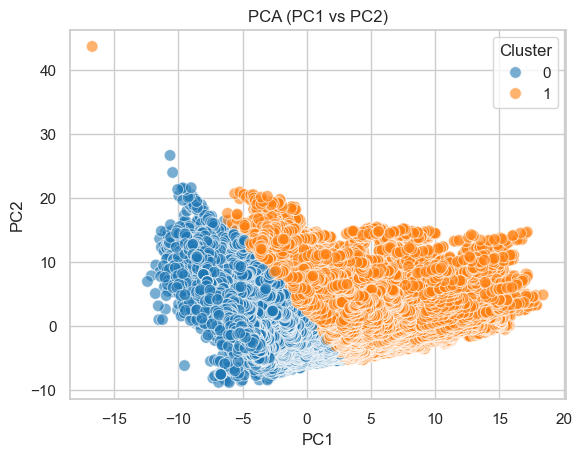

In [90]:
#Plot Cluster
# Convert PCA output
pca_df = pd.DataFrame(pcaX, columns=[f'PC{i+1}' for i in range(6)])

# Add cluster labels
pca_df['cluster'] = df['cluster'].values

# Plot PC1 vs PC2
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10',
    s=70,
    alpha=0.6
)
plt.legend(title='Cluster', loc='upper right')
plt.title('PCA (PC1 vs PC2)')
plt.show()